# TP1 : Classification des fleurs d'Iris avec les k plus proches voisins (KNN)

Objectif : construire un modèle KNN qui prédit l'espèce d'une fleur d'iris (setosa, versicolor, virginica) à partir de 4 mesures.

## 1. Chargement et exploration des données

In [1]:
#chargement de données
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mglearn
from pandas.plotting import scatter_matrix
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

iris_dataset = load_iris()

#affichage des clés
print("Clés iris_dataset: \n{}".format(iris_dataset.keys()))

#Description du dataset iris
print(iris_dataset['DESCR'][:193] + "\n...")

#Noms des classes
print("Noms des classes : \n{}\n".format(iris_dataset['target_names']))

#Noms des caractéristiques
print("Description des caractéristiques : \n{}\n".format(iris_dataset['feature_names']))

#Type du tableau de données
print("Type du tableau de données : \n{}\n".format(type(iris_dataset['data'])))

#La structure de données
print("Structure de données : \n{}\n".format(iris_dataset['data'].shape))

Clés iris_dataset: 
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive 
...
Noms des classes : 
['setosa' 'versicolor' 'virginica']

Description des caractéristiques : 
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Type du tableau de données : 
<class 'numpy.ndarray'>

Structure de données : 
(150, 4)



In [2]:
#Valeurs des caractéristiques pour les cinq premiers exemples
print("Valeurs des caractéristiques pour les cinq premiers exemples : \n{}".format(iris_dataset['data'][:5]))

#Le tableau des cibles contient les sortes d'iris déjà mesurées, également sous forme de tableau NumPy
print("Le type du tableau cibles : \n{}".format(type(iris_dataset['target'])))

#La cible est un tableau unidimensionnel, un élément pour chaque fleur
print("Forme du tableau target: \n{}".format(iris_dataset['target'].shape))

#Les sortes sont encodées sous forme d'entiers de 0 à 2 :
print("Réponses:\n{}".format(iris_dataset['target']))

#Les noms correspondant aux valeurs numériques
print("Noms des cibles: \n{}".format(iris_dataset['target_names']))

Valeurs des caractéristiques pour les cinq premiers exemples : 
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Le type du tableau cibles : 
<class 'numpy.ndarray'>
Forme du tableau target: 
(150,)
Réponses:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
Noms des cibles: 
['setosa' 'versicolor' 'virginica']


## 2. Séparation entraînement / test (75 % / 25 %)

In [3]:
#Appelons la fonction train_test_split
X_train, X_test, y_train, y_test = train_test_split(iris_dataset['data'], iris_dataset['target'], random_state=0)

#La sortie de la fonction train_test_split
print("La forme du tableau X_train : \n{}".format(X_train.shape))
print("La forme du tableau y_train : \n{}".format(y_train.shape))

print("La forme du tableau X_test : \n{}".format(X_test.shape))
print("La forme du tableau y_test : \n{}".format(y_test.shape))

La forme du tableau X_train : 
(112, 4)
La forme du tableau y_train : 
(112,)
La forme du tableau X_test : 
(38, 4)
La forme du tableau y_test : 
(38,)


## 3. Visualisation : matrice de dispersion

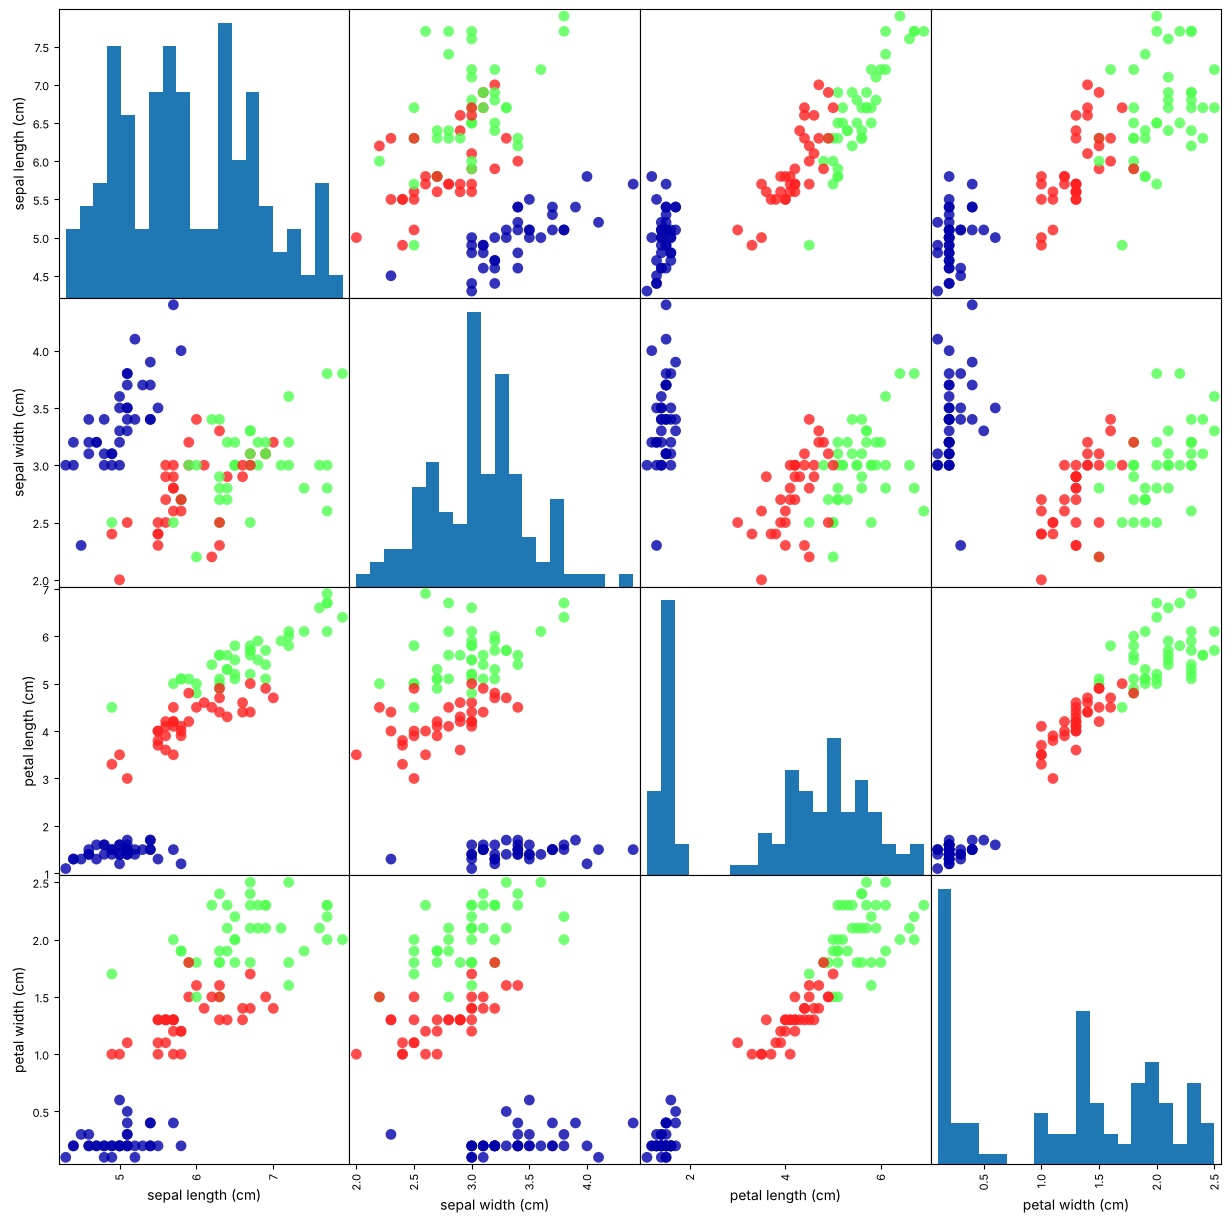

In [4]:
# crée un dataframe à partir des données du tableau X_train
# colonnes étiquetées à l'aide de iris_dataset.feature_names
iris_dataframe = pd.DataFrame(X_train, columns=iris_dataset.feature_names)

#créer une matrice de dispersion à partir du dataframe, la couleur des points est définie par y_train.
grr = scatter_matrix(iris_dataframe, c=y_train, figsize=(15, 15), marker='o',
                     hist_kwds={'bins': 20}, s=60, alpha=.8, cmap=mglearn.cm3)
plt.show()

## 4. Construction du modèle KNN (k = 1)

In [5]:
#crée un modèle knn
knn = KNeighborsClassifier(n_neighbors=1)

#Appelons fit pour construire le modèle à partir des données d'entraînement
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 5. Prédiction pour une nouvelle fleur

In [6]:
#Obtenir des prévisions
X_new = np.array([[5, 2.9, 1, 0.2]])
print("Forme du tableau X_new: {}".format(X_new.shape))

prediction = knn.predict(X_new)
print("Prédiction: {}".format(prediction))
print("Résultat prédiction: \n{}".format(iris_dataset['target_names'][prediction]))

Forme du tableau X_new: (1, 4)
Prédiction: [0]
Résultat prédiction: 
['setosa']


## 6. Évaluation du modèle

In [7]:
#Evaluation du Modèle
y_pred = knn.predict(X_test)
print("Prédictions pour le jeu de test:\n {}".format(y_pred))

print("Pourcentage d'exactitude (np.mean): {:.2f}".format(np.mean(y_pred == y_test)))
print("Pourcentage d'exactitude (knn.score): {:.2f}".format(knn.score(X_test, y_test)))

Prédictions pour le jeu de test:
 [2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0 2 1 0 2 2 1 0
 2]
Pourcentage d'exactitude (np.mean): 0.97
Pourcentage d'exactitude (knn.score): 0.97


## 7. Bonus : influence du nombre de voisins k

 k  exactitude_train  exactitude_test
 1          1.000000         0.973684
 2          0.964286         0.973684
 3          0.964286         0.973684
 4          0.973214         0.973684
 5          0.973214         0.973684
 6          0.964286         0.973684
 7          0.973214         0.973684
 8          0.973214         0.973684
 9          0.964286         0.973684
10          0.973214         0.973684
11          0.964286         0.973684
12          0.973214         0.973684
13          0.964286         0.973684
14          0.964286         0.973684
15          0.964286         0.973684
16          0.964286         0.973684
17          0.964286         0.973684
18          0.964286         0.973684
19          0.964286         0.973684
20          0.964286         0.973684


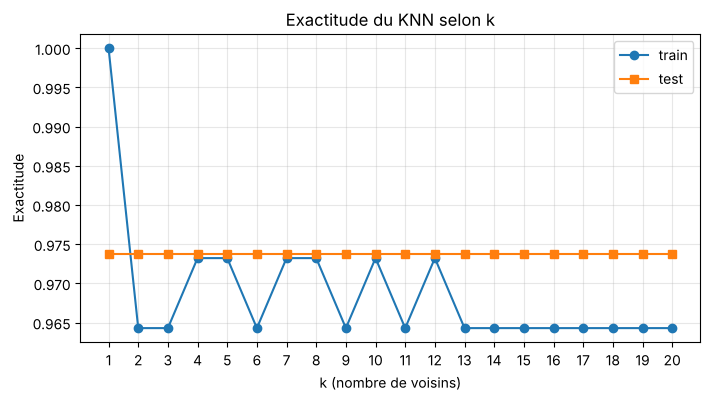

In [8]:
scores = []
ks = range(1, 21)
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    scores.append((k, m.score(X_train, y_train), m.score(X_test, y_test)))
res = pd.DataFrame(scores, columns=['k', 'exactitude_train', 'exactitude_test'])
print(res.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(res.k, res.exactitude_train, 'o-', label='train')
plt.plot(res.k, res.exactitude_test, 's-', label='test')
plt.xlabel('k (nombre de voisins)'); plt.ylabel('Exactitude'); plt.xticks(list(ks))
plt.title('Exactitude du KNN selon k'); plt.legend(); plt.grid(alpha=.3)
plt.show()

## Conclusion

Avec k = 1, le modèle KNN atteint **97 %** d'exactitude sur le jeu de test : il classe correctement 37 fleurs sur 38. La nouvelle fleur `[5, 2.9, 1, 0.2]` est prédite comme **setosa**.